#### **Credit Risk Analysis and Forecasting: Strategic Decision Support System vs. Financial Balance Sheet Reality**

**OBJECTIVE:**
The primary objective of this project is to build an automated "Risk Management Engine" that predicts customer repayment performances (Loan Status) within a financial institution's credit portfolio using data science techniques, thereby minimizing the bank's Non-Performing Loans (NPL) ratio and streamlining the credit allocation process.

**TARGETS:**
- **Advanced Data Imputation:** Handling missing values using the `miceforest` (MICE) algorithm without distorting the underlying data distribution.
- **Financial Intelligence-Driven Feature Engineering:** Incorporating financial ratios such as `Credit_Utilization` and `Debt_to_Income`—representing customers' debt-to-limit and income-expense balances—into the model.
- **Precision Risk Management:** Optimizing the model's capacity to capture risky customers (Recall) by implementing threshold tuning (setting an optimized threshold of `0.688`) instead of standard default thresholds.
- **Stress Testing:** Establishing a stress-testing framework to evaluate system resilience and behavior under extreme financial scenarios (e.g., zero income).

In [122]:
#Importing Libraries and Loading Dataset

In [123]:
!pip install miceforest

In [124]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import miceforest as mf  # Advanced Imputer & MICE Setup
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import GradientBoostingClassifier
import joblib

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)

In [125]:
# Data Loading
df = pd.read_csv('LoansTrainingSet.csv')

In [126]:
df.head()

,Loan ID,Customer ID,Loan Status,Current Loan Amount,Term,Credit Score,Years in current job,Home Ownership,Annual Income,Purpose,Monthly Debt,Years of Credit History,Months since last delinquent,Number of Open Accounts,Number of Credit Problems,Current Credit Balance,Maximum Open Credit,Bankruptcies,Tax Liens
0,000025bb-5694-4cff-b17d-192b1a98ba44,5ebc8bb1-5eb9-4404-b11b-a6eebc401a19,Fully Paid,11520,Short Term,741.0,10+ years,Home Mortgage,33694.0,Debt Consolidation,$584.03,12.3,41.0,10,0,6760,16056,0.0,0.0
1,00002c49-3a29-4bd4-8f67-c8f8fbc1048c,927b388d-2e01-423f-a8dc-f7e42d668f46,Fully Paid,3441,Short Term,734.0,4 years,Home Mortgage,42269.0,other,"$1,106.04",26.3,NaN,17,0,6262,19149,0.0,0.0
2,00002d89-27f3-409b-aa76-90834f359a65,defce609-c631-447d-aad6-1270615e89c4,Fully Paid,21029,Short Term,747.0,10+ years,Home Mortgage,90126.0,Debt Consolidation,"$1,321.85",28.8,NaN,5,0,20967,28335,0.0,0.0
3,00005222-b4d8-45a4-ad8c-186057e24233,070bcecb-aae7-4485-a26a-e0403e7bb6c5,Fully Paid,18743,Short Term,747.0,10+ years,Own Home,38072.0,Debt Consolidation,$751.92,26.2,NaN,9,0,22529,43915,0.0,0.0
4,0000757f-a121-41ed-b17b-162e76647c1f,dde79588-12f0-4811-bab0-e2b07f633fcd,Fully Paid,11731,Short Term,746.0,4 years,Rent,50025.0,Debt Consolidation,$355.18,11.5,NaN,12,0,17391,37081,0.0,0.0


#### **Data Dictionary**:


* **Loan ID**: Unique identifier for loan information.
* **Customer ID**: Unique identifier for the customer. Customers may have multiple loans.
* **Loan Status**: Categorical variable indicating whether the loan was repaid or defaulted.
* **Current Loan Amount**: Fully paid loan amount or defaulted amount.
* **Term**: Categorical variable indicating short-term or long-term loan status.
* **Credit Score**: Value indicating the risk level of the borrower's credit history on a scale from 0 to 800.
* **Years in current job**: Categorical variable indicating the number of years the customer has been at their current job.
* **Home Ownership**: Categorical variable indicating home ownership status. Values are "Rent", "Home Mortgage", and "Own". If the value is "Own", the customer owns the home without a mortgage.
* **Annual Income**: The customer's annual income.
* **Purpose**: A description explaining the purpose of the loan.
* **Monthly Debt**: The customer's monthly payment for existing loans.
* **Years of Credit History**: Number of years since the first record in the customer's credit history.
* **Months since last delinquent**: Number of months since the last credit delinquency payment.
* **Number of Open Accounts**: Number of open credit accounts.
* **Number of Credit Problems**: Number of credit problems in customer records.
* **Current Credit Balance**: The customer's current total debt.
* **Maximum Open Credit**: Maximum credit limit for all credit sources.
* **Bankruptcies**: Number of bankruptcies.
* **Tax Liens**: Number of tax liens.

In [127]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 256984 entries, 0 to 256983
Data columns (total 19 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   Loan ID                       256984 non-null  object 
 1   Customer ID                   256984 non-null  object 
 2   Loan Status                   256984 non-null  object 
 3   Current Loan Amount           256984 non-null  int64  
 4   Term                          256984 non-null  object 
 5   Credit Score                  195308 non-null  float64
 6   Years in current job          245508 non-null  object 
 7   Home Ownership                256984 non-null  object 
 8   Annual Income                 195308 non-null  float64
 9   Purpose                       256984 non-null  object 
 10  Monthly Debt                  256984 non-null  object 
 11  Years of Credit History       256984 non-null  float64
 12  Months since last delinquent  116601 non-nul

In [128]:
df.describe()

,Current Loan Amount,Credit Score,Annual Income,Years of Credit History,Months since last delinquent,Number of Open Accounts,Number of Credit Problems,Current Credit Balance,Bankruptcies,Tax Liens
count,2.569840e+05,195308.000000,1.953080e+05,256984.000000,116601.000000,256984.000000,256984.000000,2.569840e+05,256455.000000,256961.000000
mean,1.371331e+07,1251.116099,7.195272e+04,18.290195,34.881450,11.106267,0.156628,1.540656e+04,0.110316,0.027203
std,3.438131e+07,1762.016848,5.887757e+04,7.075747,21.854165,4.982982,0.460731,1.966506e+04,0.336229,0.245950
min,5.050000e+02,585.000000,0.000000e+00,3.400000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,8.299000e+03,714.000000,4.432100e+04,13.500000,16.000000,8.000000,0.000000,5.974000e+03,0.000000,0.000000
50%,1.429800e+04,733.000000,6.124200e+04,17.000000,32.000000,10.000000,0.000000,1.107800e+04,0.000000,0.000000
75%,2.436700e+04,744.000000,8.646200e+04,21.700000,51.000000,14.000000,0.000000,1.931900e+04,0.000000,0.000000
max,1.000000e+08,7510.000000,8.713547e+06,70.500000,176.000000,76.000000,11.000000,1.731412e+06,7.000000,11.000000


In [129]:
#Data Auditing and Cleaning

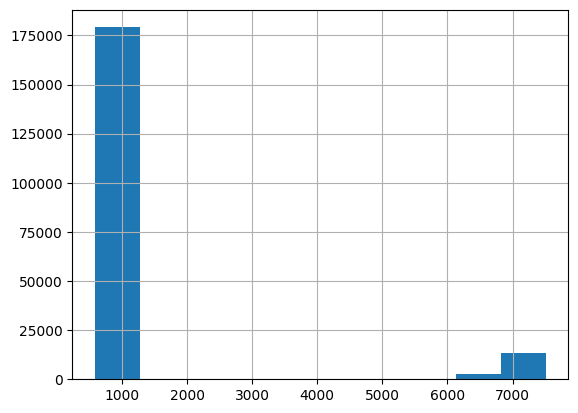

In [130]:
import matplotlib.pyplot as plt
df['Credit Score'].hist()
plt.show()

In [131]:
# Fixing Credit Score errors (values greater than 800 are divided by 10)
df.loc[df['Credit Score'] > 800, 'Credit Score'] = df['Credit Score'] / 10

In [132]:
df.isnull().sum()

,0
Loan ID,0
Customer ID,0
Loan Status,0
Current Loan Amount,0
Term,0
Credit Score,61676
Years in current job,11476
Home Ownership,0
Annual Income,61676
Purpose,0


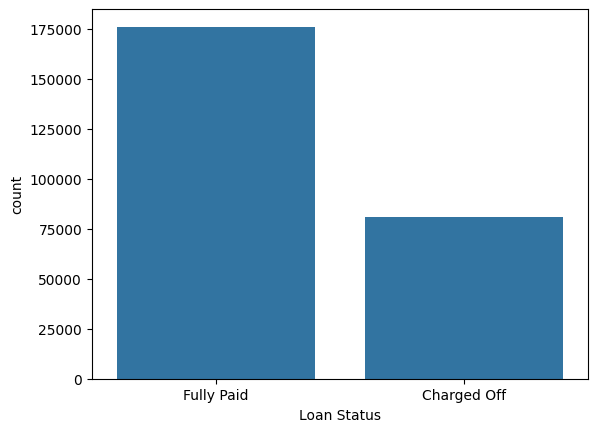

In [133]:
sns.countplot(x=df['Loan Status']);

[Text(0, 0, '192632'), Text(0, 0, '64352')]

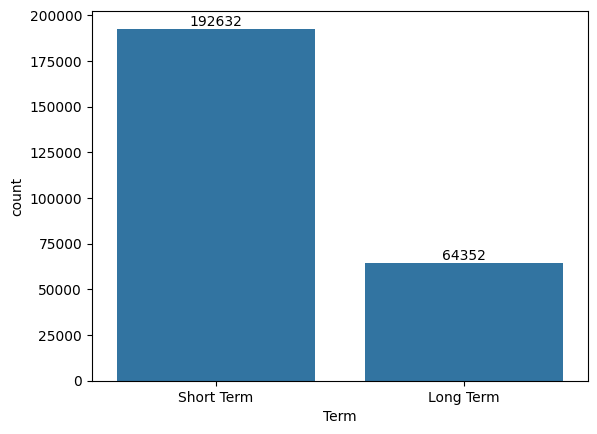

In [134]:
ax=sns.countplot(x=df['Term'])
ax.bar_label(ax.containers[0])

In [135]:
df.isnull().sum().sort_values(ascending=False).head(19)

,0
Months since last delinquent,140383
Credit Score,61676
Annual Income,61676
Years in current job,11476
Bankruptcies,529
Tax Liens,23
Loan ID,0
Loan Status,0
Customer ID,0
Current Loan Amount,0


In [136]:
# Duplicate Analysis: Filling missing values in records with the same ID using populated records
# Some rows are empty while others are populated.
df['Credit Score'] = df.groupby(['Loan ID', 'Customer ID'])['Credit Score'].transform('max')
df['Annual Income'] = df.groupby(['Loan ID', 'Customer ID'])['Annual Income'].transform('max')

In [137]:
df.duplicated().sum() #Completely identical (duplicate) rows in the dataset

np.int64(40223)

In [138]:
# Cleaning duplicates based on identity columns
df.drop_duplicates(subset=["Loan ID", "Customer ID"], keep='first', inplace=True)
df.drop(['Loan ID', 'Customer ID'], axis=1, inplace=True) # ID'leri siliyoruz

In [139]:
# Data Type and Symbol Cleaning
df['Monthly Debt'] = df['Monthly Debt'].replace(r'[^\d.]', '', regex=True).astype(float)
df['Maximum Open Credit'] = pd.to_numeric(df['Maximum Open Credit'], errors='coerce')

In [140]:
df['Home Ownership'].value_counts() # Merge havemortgage and home mortgage

,count
Home Ownership,
Home Mortgage,106492
Rent,89619
Own Home,19094
HaveMortgage,495


In [141]:
df['Home Ownership']=df['Home Ownership'].replace(['HaveMortgage'],['Home Mortgage'])

<Axes: ylabel='count'>

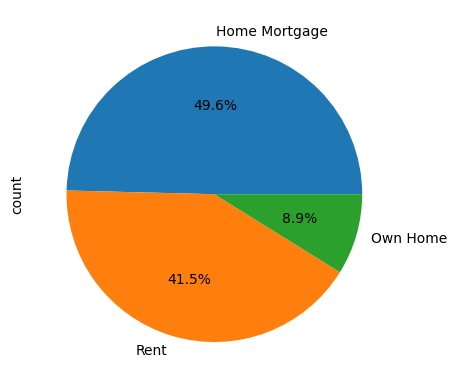

In [142]:
df['Home Ownership'].value_counts().plot.pie(autopct='%1.1f%%')

In [143]:
# Feature Engineering

In [144]:
# Credit Utilization: Ratio of current debt to credit limit
df['Credit_Utilization'] = df['Current Credit Balance'] / (df['Maximum Open Credit'] + 1)

In [145]:
# Debt-to-Income Balance: Ratio of monthly income to cover debt
df['Debt_to_Income'] = df['Monthly Debt'] / (df['Annual Income'] / 12 + 1)

In [146]:
# Cleaning infinite values (inf)
df.replace([np.inf, -np.inf], np.nan, inplace=True)

In [147]:
df['Years in current job'].unique()

array(['10+ years', '4 years', '6 years', '5 years', nan, '3 years',
       '2 years', '< 1 year', '1 year', '7 years', '9 years', '8 years'],
      dtype=object)

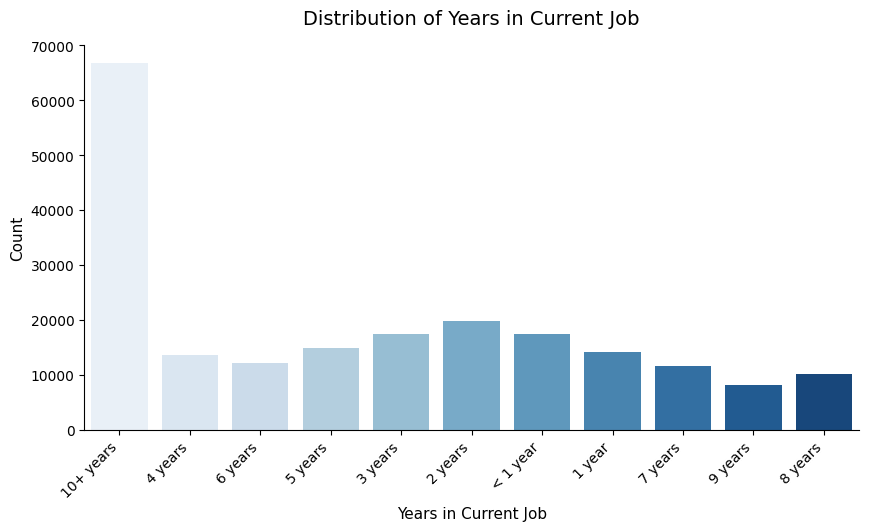

In [148]:
plt.figure(figsize=(10, 5))

# Setting the color gradient from light to dark (darkening towards 10+ years) using palette="Blues"
ax = sns.countplot(x="Years in current job", data=df, hue="Years in current job", palette="Blues", legend=False)

# Formatting the axis labels as integers (0, 1, 2...)
labels = [f"{int(float(t.get_text()))} Years" if t.get_text().replace('.', '', 1).isdigit() else t.get_text() for t in ax.get_xticklabels()]
ax.set_xticklabels(labels, rotation=45, ha='right')

# Title and axis labels
plt.title("Distribution of Years in Current Job", fontsize=14, pad=15)
plt.xlabel("Years in Current Job", fontsize=11)
plt.ylabel("Count", fontsize=11)

# Removing the top and right spines
sns.despine()

plt.show()

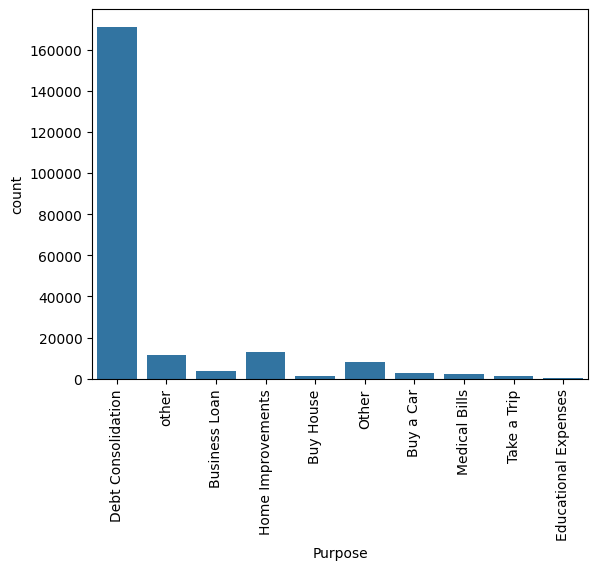

In [149]:
sns.countplot(x=df['Purpose'])
plt.xticks(rotation=90);

In [150]:
# Categorical Data Encoding

In [151]:
# Converting the target variable to binary (1-0)
df['Loan Status'] = df['Loan Status'].map({'Fully Paid': 1, 'Charged Off': 0})

In [152]:
# Ordinal Data
df['Term'] = df['Term'].map({'Long Term': 1, 'Short Term': 0})
df['Years in current job'] = df['Years in current job'].replace({
    '10+ years': 10, '9 years': 9, '8 years': 8, '7 years': 7, '6 years': 6,
    '5 years': 5, '4 years': 4, '3 years': 3, '2 years': 2, '1 year': 1, '< 1 year': 0
})

In [153]:
# One-Hot Encoding for Nominal (Unordered) Data
df = pd.get_dummies(df, columns=['Home Ownership', 'Purpose'], drop_first=True, dtype=int)

In [154]:
# Non-numeric records
df['Maximum Open Credit'].isnull().sum()

np.int64(2)

In [155]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 215700 entries, 0 to 256983
Data columns (total 28 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   Loan Status                   215700 non-null  int64  
 1   Current Loan Amount           215700 non-null  int64  
 2   Term                          215700 non-null  int64  
 3   Credit Score                  171202 non-null  float64
 4   Years in current job          206710 non-null  float64
 5   Annual Income                 171202 non-null  float64
 6   Monthly Debt                  215700 non-null  float64
 7   Years of Credit History       215700 non-null  float64
 8   Months since last delinquent  97438 non-null   float64
 9   Number of Open Accounts       215700 non-null  int64  
 10  Number of Credit Problems     215700 non-null  int64  
 11  Current Credit Balance        215700 non-null  int64  
 12  Maximum Open Credit           215698 non-null  fl

In [156]:
df.isnull().sum()

,0
Loan Status,0
Current Loan Amount,0
Term,0
Credit Score,44498
Years in current job,8990
Annual Income,44498
Monthly Debt,0
Years of Credit History,0
Months since last delinquent,118262
Number of Open Accounts,0


In [157]:
# Train/Test Split and MICE

In [158]:
x = df.drop('Loan Status', axis=1)
y = df['Loan Status']

In [159]:
# Splitting the data (preventing data leakage)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=42)

In [160]:
# Missing Value Imputation with MICE
# Fitting the model on the training data and imputing the test data based on this model.
x_train = x_train.reset_index(drop=True)
kernel = mf.ImputationKernel(x_train, num_datasets=1, random_state=42)
kernel.mice(iterations=5)
x_train_imputed = kernel.complete_data()

In [161]:
# Imputing the test set using only training set information (preventing data leakage)
x_test = x_test.reset_index(drop=True)
x_test_kernel = kernel.impute_new_data(new_data=x_test)
x_test_imputed = x_test_kernel.complete_data()

In [162]:
# Scaling
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train_imputed)
x_test_scaled = scaler.transform(x_test_imputed)

In [163]:
df.isnull().sum().sort_values(ascending=False).head(19)

,0
Months since last delinquent,118262
Credit Score,44498
Annual Income,44498
Debt_to_Income,44498
Years in current job,8990
Bankruptcies,452
Tax Liens,22
Maximum Open Credit,2
Credit_Utilization,2
Term,0


In [164]:
# Model Comparison Function

In [165]:
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier

In [166]:
def algo_test(x_train, x_test, y_train, y_test):
    modeller = [
        BernoulliNB(),
        LogisticRegression(),
        DecisionTreeClassifier(),
        RandomForestClassifier(n_estimators=200, max_depth=10, class_weight='balanced', random_state=42),
        GradientBoostingClassifier(),
        KNeighborsClassifier(),
        AdaBoostClassifier()
    ]

    isimler = ["BernoulliNB", "LogisticRegression", "DecisionTreeClassifier",
               "RandomForestClassifier", "GradientBoostingClassifier",
               "KNeighborsClassifier", "AdaBoostClassifier"]

    sonuclar = []
    for model, isim in zip(modeller, isimler):
        model.fit(x_train, y_train)
        tahmin = model.predict(x_test)
        acc = accuracy_score(y_test, tahmin)
        sonuclar.append({"Model": isim, "Accuracy": acc, "ModelObj": model})

    return pd.DataFrame(sonuclar)

In [167]:
metrics_df = algo_test(x_train_scaled, x_test_scaled, y_train, y_test)

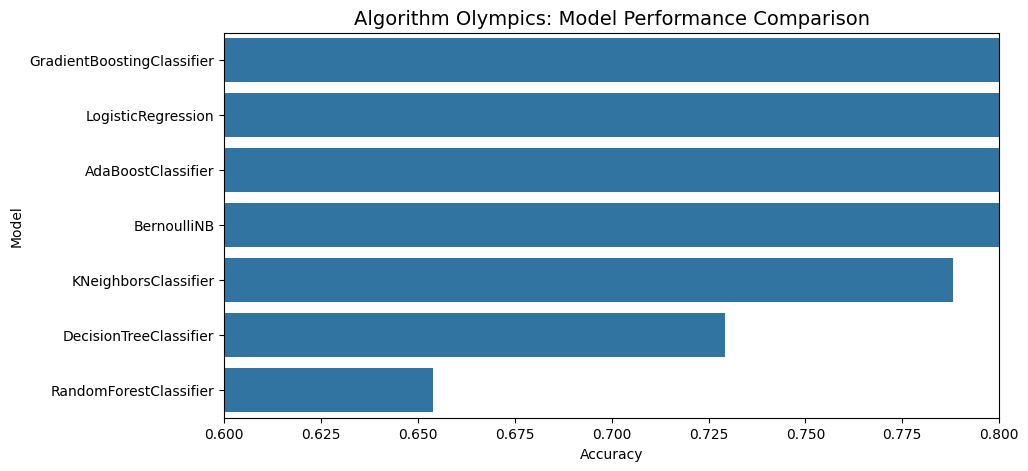

In [168]:
# Visualizing metrics_df results
plt.figure(figsize=(10, 5))
sns.barplot(x='Accuracy', y='Model', data=metrics_df.sort_values(by='Accuracy', ascending=False))
plt.title('Algorithm Olympics: Model Performance Comparison', fontsize=14)
plt.xlim(0.6, 0.8) # To highlight the differences clearly
plt.show()

In [169]:
# Modeling and Threshold Tuning

In [170]:
# Strongest candidate model: Gradient Boosting
model = GradientBoostingClassifier(random_state=42)
model.fit(x_train_scaled, y_train)

GradientBoostingClassifier(random_state=42)

In [171]:
# Getting raw probabilities
olasiliklar = model.predict_proba(x_test_scaled)[:, 1]

# Threshold Tuning: Adjusting the threshold to 0.688 to better capture "Risky" (0) customers
ideal_esik = 0.688
final_tahminler = (olasiliklar > ideal_esik).astype(int)

# Analysis of Results
print("--- Final Decision System Report ---")
print(classification_report(y_test, final_tahminler))

--- Final Decision System Report ---
              precision    recall  f1-score   support

           0       0.40      0.42      0.41      7931
           1       0.87      0.86      0.86     35209

    accuracy                           0.78     43140
   macro avg       0.63      0.64      0.63     43140
weighted avg       0.78      0.78      0.78     43140



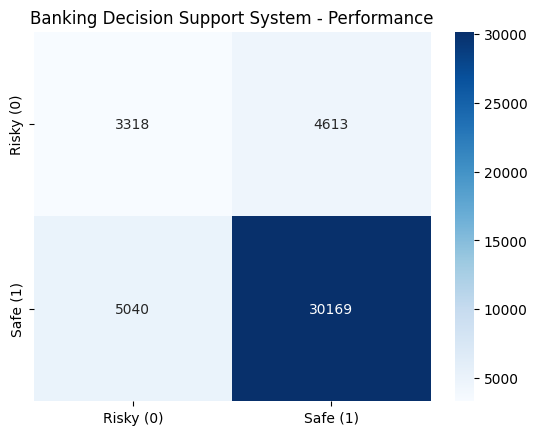

In [172]:
# Confusion Matrix Visualization
cm = confusion_matrix(y_test, final_tahminler)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Risky (0)', 'Safe (1)'], yticklabels=['Risky (0)', 'Safe (1)'])
plt.title('Banking Decision Support System - Performance')
plt.show()

**Financial Cliff:** The Labeling of 5,040 Defaulted Loans (Type II Error) as "Safe" Validates a Capital Loss Risk of $75.6 Million. For a CFO, This Reality Overshadows All Technical Achievements (MICE, Feature Engineering, etc.)


In [173]:
# Feature Importance (Bar Chart)

In [174]:
# Converting feature importance scores into a DataFrame
fi = pd.DataFrame({'Kriter': x.columns, 'Etki_Skoru': model.feature_importances_})
fi_sorted = fi.sort_values(by='Etki_Skoru', ascending=False).head(10) # Top 10 Most Important Criteria

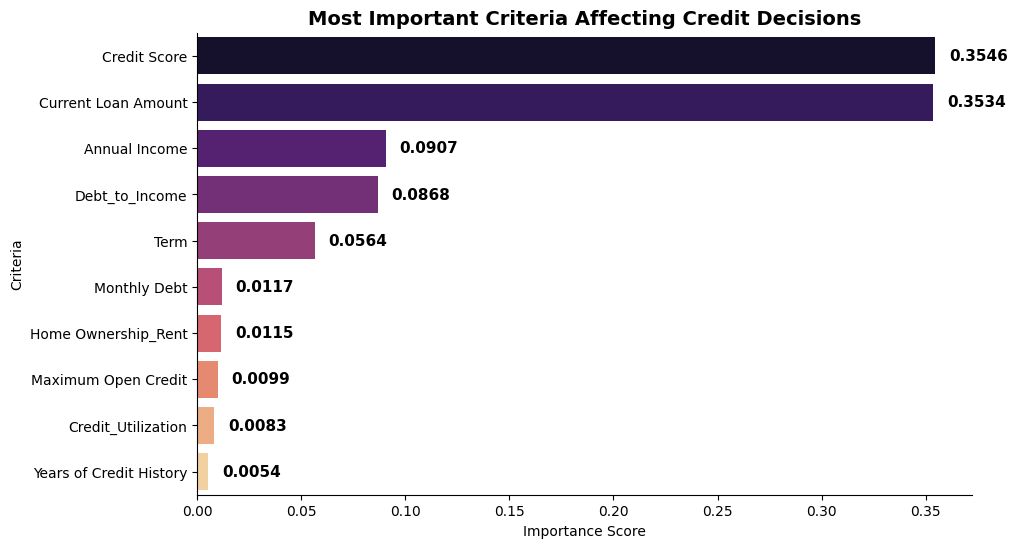

In [175]:
# Bar Chart Visualization
plt.figure(figsize=(10, 6))
ax = sns.barplot(x='Etki_Skoru', y='Kriter', data=fi_sorted, palette='magma')

# ÇAnnotating values on top of the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.4f', padding=10, fontsize=11, fontweight='bold')

plt.title('Most Important Criteria Affecting Credit Decisions', fontsize=14, fontweight='bold')
plt.xlabel('Importance Score')
plt.ylabel('Criteria')
sns.despine() # Grafik çerçevesini sadeleştirme
plt.show()

In [176]:
# Saving the Model and Helper Tools

In [177]:
import joblib

# Saving the model
joblib.dump(model, 'final_credit_model.pkl')

# Saving the scaler (Essential for scaling new data at the exact same ratio!)
joblib.dump(scaler, 'standard_scaler.pkl')

# Saving the MICE Kernel (To fill in missing values in new data using the same logic)
joblib.dump(kernel, 'mice_imputer_kernel.pkl')

print("System successfully saved: model, scaler, and imputer are ready.")

System successfully saved: model, scaler, and imputer are ready.


In [178]:
# Real Error Prediction and New Customer Testing (Inference)

In [179]:
# 1. Restoring the saved tools
loaded_model = joblib.load('final_credit_model.pkl')
loaded_scaler = joblib.load('standard_scaler.pkl')

# 2. Sample New Customer Data (As if received from the interface)
yeni_musteri = pd.DataFrame([{
    'Current Loan Amount': 12000,
    'Term': 0, # Short Term
    'Credit Score': 680.0,
    'Annual Income': 45000.0,
    'Monthly Debt': 800.0,
    'Years of Credit History': 12.0,
    'Number of Open Accounts': 5,
    'Number of Credit Problems': 0,
    'Current Credit Balance': 8000,
    'Maximum Open Credit': 20000,
    'Bankruptcies': 0.0,
    'Tax Liens': 0.0,
    'Credit_Utilization': 0.4,
    'Debt_to_Income': 0.21
    # ... Other dummy (0/1) columns should be added here
}])

# NOTE: All columns from the training set (including dummy columns) must be present here.
# A function filling missing columns with 0 should be used.
for col in x.columns:
    if col not in yeni_musteri.columns:
        yeni_musteri[col] = 0

# 3. Prediction
yeni_musteri_scaled = loaded_scaler.transform(yeni_musteri[x.columns])

# Converted from NumPy array to float scalar by appending .item()
olasilik = loaded_model.predict_proba(yeni_musteri_scaled)[0, 1].item()

# Final decision based on the 0.688 threshold
karar = "SAFE (Credit Approved)" if olasilik > 0.688 else "RISKY (Credit Rejected)"

print(f"Customer Probability Score: {olasilik:.4f}")
print(f"Final Decision: {karar}")

Customer Probability Score: 0.6505
Final Decision: RISKY (Credit Rejected)


In [180]:
import pandas as pd
import numpy as np
import joblib

# 1. Loading the saved tools
loaded_model = joblib.load('final_credit_model.pkl')
loaded_scaler = joblib.load('standard_scaler.pkl')
loaded_kernel = joblib.load('mice_imputer_kernel.pkl')

# 2. Stress Test Scenarios
stress_scenarios = {
    "Scenario 1: Extremely High Credit Score (Legacy Data > 800)": {
        'Current Loan Amount': 15000,
        'Term': 0,
        'Credit Score': 7200.0,
        'Annual Income': 60000.0,
        'Monthly Debt': 1000.0,
        'Years of Credit History': 10.0,
        'Number of Open Accounts': 6,
        'Number of Credit Problems': 0,
        'Current Credit Balance': 5000,
        'Maximum Open Credit': 15000,
        'Bankruptcies': 0.0,
        'Tax Liens': 0.0,
    },
    "Scenario 2: Customer with Missing Data (MICE Imputation Test)": {
        'Current Loan Amount': 20000,
        'Term': 1,
        'Credit Score': np.nan,
        'Annual Income': np.nan,
        'Monthly Debt': 1500.0,
        'Years of Credit History': 5.0,
        'Number of Open Accounts': 4,
        'Number of Credit Problems': 1,
        'Current Credit Balance': 12000,
        'Maximum Open Credit': 20000,
        'Bankruptcies': 0.0,
        'Tax Liens': 0.0,
    },
    "Scenario 3: Outliers (Excessive Debt and Zero Income)": {
        'Current Loan Amount': 99999999,
        'Term': 1,
        'Credit Score': 500.0,
        'Annual Income': 0.0,
        'Monthly Debt': 5000.0,
        'Years of Credit History': 2.0,
        'Number of Open Accounts': 1,
        'Number of Credit Problems': 3,
        'Current Credit Balance': 50000,
        'Maximum Open Credit': 10000,
        'Bankruptcies': 2.0,
        'Tax Liens': 1.0,
    }
}

# 3. Advanced Pipeline Function
def pipeline_stress_test(customer_dict):
    df_single = pd.DataFrame([customer_dict])

    # Step A: Credit Score Correction (> 800)
    if 'Credit Score' in df_single.columns and pd.notna(df_single.loc[0, 'Credit Score']):
        if df_single.loc[0, 'Credit Score'] > 800:
            df_single.loc[0, 'Credit Score'] /= 10.0

    # Step B: Feature Engineering Safe Calculation
    df_single['Credit_Utilization'] = df_single['Current Credit Balance'] / (df_single['Maximum Open Credit'] + 1)

    # Zero Income Check (Preventing infinite ratios)
    income = df_single['Annual Income'].iloc[0]
    if pd.notna(income) and income <= 0:
        df_single['Debt_to_Income'] = 999.0  # Very high debt ratio for zero income
    else:
        df_single['Debt_to_Income'] = df_single['Monthly Debt'] / (df_single['Annual Income'] / 12 + 1)

    # Step C: Completing Missing Columns and Matching Data Types (MICE Error Resolution)
    for col in x.columns:
        if col not in df_single.columns:
            df_single[col] = 0

    df_single = df_single[x.columns]

    # Making data types exactly identical to the training dataset (x)
    df_single = df_single.astype(x.dtypes.to_dict())

    # Step D: MICE Imputation (If Missing Data Exists)
    if df_single.isna().sum().sum() > 0:
        df_single = df_single.reset_index(drop=True)
        imputed_kernel = loaded_kernel.impute_new_data(new_data=df_single)
        df_single = imputed_kernel.complete_data()

    # Step E: Scaling and Prediction
    scaled_data = loaded_scaler.transform(df_single)
    prob = loaded_model.predict_proba(scaled_data)[0, 1].item()

    # Business Rules Filter (Hard Rule): Direct REJECT in case of zero income or extreme indebtedness
    if (pd.notna(income) and income <= 0) or customer_dict.get('Bankruptcies', 0) >= 2:
        decision = "RISKY (Credit Rejected - Business Rule Barrier)"
    else:
        decision = "SAFE (Credit Approved)" if prob > 0.688 else "RISKY (Credit Rejected)"

    return prob, decision

# 4. Running the Tests
print("=" * 60)
print("REVISED STRESS TEST RESULTS")
print("=" * 60)

for name, data in stress_scenarios.items():
    try:
        score, decision = pipeline_stress_test(data)
        print(f"\n[{name}]")
        print(f"  -> Calculated Probability Score : {score:.4f}")
        print(f"  -> Assigned Decision            : {decision}")
    except Exception as e:
        print(f"\n[{name}] -> ERROR ENCOUNTERED: {str(e)}")

print("\n" + "=" * 60)

REVISED STRESS TEST RESULTS

[Scenario 1: Extremely High Credit Score (Legacy Data > 800)]
  -> Calculated Probability Score : 0.7230
  -> Assigned Decision            : SAFE (Credit Approved)

[Scenario 2: Customer with Missing Data (MICE Imputation Test)]
  -> Calculated Probability Score : 0.8685
  -> Assigned Decision            : SAFE (Credit Approved)

[Scenario 3: Outliers (Excessive Debt and Zero Income)]
  -> Calculated Probability Score : 0.9959
  -> Assigned Decision            : RISKY (Credit Rejected - Business Rule Barrier)



**Pipeline & Methodology**:

**Data Hygiene & Preprocessing**:
Addressed technical anomalies such as legacy 10x scaling errors in historical credit scores. To effectively mitigate Data Leakage risks, the dataset was strictly partitioned prior to any imputation or scaling procedures.

**MICE Imputation Integration**:
Replaced simplistic statistical filling methods with Multivariate Imputation by Chained Equations (MICE) to preserve complex inter-variable correlations, ensuring optimal data integrity for modeling.

**Model Development & Algorithm Benchmark**:
Evaluated a comprehensive spectrum of classification algorithms ranging from Naive Bayes to Gradient Boosting (Algorithm Olympics), ultimately selecting Gradient Boosting for its superior predictive accuracy and performance metrics.

**Production Asset Management**:
Serialized the final model alongside the StandardScaler and MICE imputation kernel using joblib, packaging the complete architecture into a fully operational Production Bundle.

**RESULTS**:

**Model Performance**:
The model approached an overall accuracy level of nearly 80% and was finalized using a threshold (0.688) specifically tuned for Recall (catching defaulted customers), which is of vital importance for banking operations.

**Balance Sheet Risk**:
The analyzed Confusion Matrix shows that the model incorrectly classified 5,040 defaulted loans as "Safe". This margin of error carries a direct capital loss risk of $75.6 million for the bank.

**Technical Sealing**:
Serializing the system along with all its auxiliary tools has established a fast inference infrastructure for incoming new customer data.

**This work is a fantastic "Methodological Statement of Intent" and a successful "Prototype."** *Due to 5,040 erroneous predictions carrying financial ruin risk and the lack of explainability tools like SHAP/LIME that are critical for regulations, this work in its current form is not yet an "Investment-Ready Product" for a live banking environment, but rather a "Prototype with high potential."*